# Prediksi Pemenang Pertandingan Tenis ATP: Random Forest vs XGBoost vs SVM

Notebook ini mencakup **Tahap 1** (model tabular) dari diskusi kita:

1. Memuat data (Jeff Sackmann, CC BY-NC-SA) dan pembersihan
2. Feature engineering **tanpa data leakage** (Elo, form, H2H, kelelahan, dll.)
3. Split berdasarkan waktu, tuning, dan pelatihan RF / XGBoost / SVM
4. Evaluasi (metrik, ROC, kalibrasi, McNemar) dan interpretasi (SHAP)
5. Aplikasi Gradio: **pemain terdaftar** dan **pemain kustom** (mis. "Jefri")

> **Penting:** jalankan sel secara berurutan. Runtime cukup CPU biasa (tanpa GPU).
> Data dibuat oleh Jeff Sackmann (https://github.com/JeffSackmann/tennis_atp, wajib disitasi di skripsi) dan diunduh dari mirror arsip di Hugging Face:
> https://huggingface.co/datasets/Aneeshers/tennis-sackmann-archive

## 0. Instalasi dan konfigurasi

In [1]:
!pip install -q xgboost shap gradio statsmodels

In [2]:
import os, warnings, joblib
from collections import defaultdict, deque
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, brier_score_loss, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42

# ===== KONFIGURASI (silakan ubah) =====
START_YEAR, END_YEAR = 2000, 2026        # rentang data dimuat (Elo dihangatkan sejak START_YEAR)
TRAIN_START_YEAR = 2010                  # data latih dimulai dari tahun ini
TEST_START_DATE = "2023-01-01"           # data uji = pertandingan sejak tanggal ini
MIN_PRIOR_MATCHES = 10                   # aturan cold-start: kedua pemain min. 10 laga sebelumnya
DROP_RETIRED = True                      # buang laga RET (mundur di tengah pertandingan)
N_TUNE = 12000                           # jumlah baris terbaru untuk tuning (agar SVM tidak terlalu lambat)
N_ITER = 60                              # maks. kombinasi hyperparameter per model (jika ruang lebih kecil, seluruh ruang dicoba)
DATA_URL = "https://huggingface.co/datasets/Aneeshers/tennis-sackmann-archive/resolve/main/atp"   # mirror arsip data Jeff Sackmann
SAVE_DIR = "/content/model_tenis"        # ganti ke '/content/drive/MyDrive/model_tenis' jika Drive di-mount
os.makedirs(SAVE_DIR, exist_ok=True)

## 1. Memuat dan membersihkan data

In [3]:
frames = []
for y in range(START_YEAR, END_YEAR + 1):
    try:
        frames.append(pd.read_csv(f"{DATA_URL}/atp_matches_{y}.csv"))
    except Exception as e:
        print(f"Gagal memuat {y}: {type(e).__name__}: {str(e)[:100]}")

if not frames:
    raise RuntimeError("Data tidak bisa dimuat. Pastikan internet Colab aktif, lalu jalankan ulang sel ini.")
print("Tahun berhasil dimuat:", len(frames), "dari", END_YEAR - START_YEAR + 1)
raw = pd.concat(frames, ignore_index=True)
print("Total baris mentah:", len(raw))

df = raw.copy()
df["tourney_date"] = pd.to_datetime(df["tourney_date"].astype(int).astype(str), format="%Y%m%d")

# buang baris tanpa info penting
df = df.dropna(subset=["surface", "winner_id", "loser_id", "winner_rank", "loser_rank"])

# buang walkover / default (dan opsional retired)
score = df["score"].fillna("")
bad = score.str.contains("W/O|DEF")
if DROP_RETIRED:
    bad |= score.str.contains("RET")
df = df[~bad]

# urutkan kronologis (penting untuk feature engineering tanpa leakage)
ROUND_ORDER = {"R128": 1, "R64": 2, "R32": 3, "R16": 4, "RR": 4, "QF": 5, "SF": 6, "BR": 6, "F": 7}
df["round_order"] = df["round"].map(ROUND_ORDER).fillna(0)
df = df.sort_values(["tourney_date", "round_order", "match_num"]).reset_index(drop=True)
print("Baris setelah pembersihan:", len(df))
df[["tourney_date", "surface", "round", "winner_name", "loser_name", "winner_rank", "loser_rank"]].head()

Tahun berhasil dimuat: 27 dari 27
Total baris mentah: 79299
Baris setelah pembersihan: 74674


,tourney_date,surface,round,winner_name,loser_name,winner_rank,loser_rank
0,2000-01-03,Hard,R32,Thomas Enqvist,Arnaud Clement,4.0,56.0
1,2000-01-03,Hard,R32,Nicolas Kiefer,Jeff Tarango,6.0,55.0
2,2000-01-03,Hard,R32,Michal Tabara,Yevgeny Kafelnikov,123.0,2.0
3,2000-01-03,Hard,R32,Roger Federer,Jens Knippschild,64.0,91.0
4,2000-01-03,Hard,R32,Cristiano Caratti,Ivo Heuberger,213.0,221.0


## 2. Feature engineering (tanpa data leakage)

Semua fitur dihitung **hanya dari pertandingan sebelumnya** lewat kelas `Tracker`. Statistik pertandingan itu sendiri
(ace, double fault, dll.) **tidak dipakai**. Posisi Pemain 1 / Pemain 2 diacak agar model tidak belajar bahwa "Pemain 1 selalu menang".

In [4]:
def _elo0(): return 1500.0
def _deque10(): return deque(maxlen=10)
def _deque60(): return deque(maxlen=60)
def _list(): return []

def expected(a, b):
    return 1.0 / (1.0 + 10 ** ((b - a) / 400.0))

class Tracker:
    """Menyimpan status setiap pemain (Elo, form, H2H, kelelahan, dll.) secara kronologis."""
    def __init__(self):
        self.elo = defaultdict(_elo0)          # Elo umum
        self.elo_s = defaultdict(_elo0)        # Elo per permukaan: key (pid, surface)
        self.n = defaultdict(int)              # jumlah laga
        self.n_s = defaultdict(int)            # jumlah laga per permukaan
        self.wins_s = defaultdict(int)         # kemenangan per permukaan
        self.form = defaultdict(_deque10)      # hasil 10 laga terakhir (1/0)
        self.load = defaultdict(_deque60)      # (tanggal, menit bermain)
        self.h2h = defaultdict(int)            # (a, b) -> jumlah kemenangan a atas b
        self.bio = {}                          # data terakhir pemain (untuk prediksi)
        self.elo_hist = defaultdict(_list)     # riwayat Elo untuk grafik

    def dynamic(self, pid, surface, date):
        """Fitur dinamis pemain SEBELUM pertandingan pada tanggal `date`."""
        ns = self.n_s[(pid, surface)]
        fatigue = sum(m for d, m in self.load[pid] if 0 <= (date - d).days <= 14)
        return dict(
            elo=self.elo[pid], elo_s=self.elo_s[(pid, surface)],
            form=float(np.mean(self.form[pid])) if self.form[pid] else 0.5,
            surf_wr=(self.wins_s[(pid, surface)] + 2.5) / (ns + 5),   # dihaluskan (prior 50%)
            fatigue=float(fatigue), exp=self.n[pid])

    def update(self, r):
        """Perbarui status SETELAH pertandingan selesai."""
        w, l, s, d = r.winner_id, r.loser_id, r.surface, r.tourney_date
        mins = r.minutes if pd.notna(r.minutes) else 100
        # Elo umum dan per permukaan (K menurun seiring jumlah laga; nilai ditetapkan penulis)
        for store, kw_n, kl_n, kw, kl in (
            (self.elo,   self.n[w],        self.n[l],        w,      l),
            (self.elo_s, self.n_s[(w, s)], self.n_s[(l, s)], (w, s), (l, s))):
            e_w = expected(store[kw], store[kl])
            store[kw] += 250 / ((kw_n + 5) ** 0.4) * (1 - e_w)
            store[kl] -= 250 / ((kl_n + 5) ** 0.4) * (1 - e_w)
        for pid, won in ((w, 1), (l, 0)):
            self.n[pid] += 1; self.n_s[(pid, s)] += 1; self.wins_s[(pid, s)] += won
            self.form[pid].append(won); self.load[pid].append((d, mins))
            self.elo_hist[pid].append((d, self.elo[pid]))
        self.h2h[(w, l)] += 1
        for pref, pid in (("winner", w), ("loser", l)):
            self.bio[pid] = dict(name=getattr(r, f"{pref}_name"), hand=getattr(r, f"{pref}_hand"),
                                 ht=getattr(r, f"{pref}_ht"), age=getattr(r, f"{pref}_age"),
                                 rank=getattr(r, f"{pref}_rank"), points=getattr(r, f"{pref}_rank_points"),
                                 last_date=d)

FEATURES = ["elo_diff", "elo_surface_diff", "rank_diff_log", "points_diff_log", "age_diff", "height_diff",
            "form_diff", "surface_wr_diff", "h2h_diff", "fatigue_diff", "experience_diff", "lefty_diff",
            "best_of_5", "is_slam", "surf_hard", "surf_clay", "surf_grass"]

def _diff(a, b):
    return 0.0 if (pd.isna(a) or pd.isna(b)) else float(a - b)

def build_features(p1, p2, surface, best_of, is_slam, h2h_diff):
    """Satu-satunya fungsi pembentuk fitur, dipakai saat pelatihan DAN saat prediksi (anti train/serve skew).
    Nilai positif = menguntungkan Pemain 1."""
    r1, r2 = p1.get("rank", np.nan), p2.get("rank", np.nan)
    rank_ok = pd.notna(r1) and pd.notna(r2) and r1 > 0 and r2 > 0
    pt1, pt2 = p1.get("points", np.nan), p2.get("points", np.nan)
    return dict(
        elo_diff=p1["elo"] - p2["elo"],
        elo_surface_diff=p1["elo_s"] - p2["elo_s"],
        rank_diff_log=float(np.log(r2 / r1)) if rank_ok else 0.0,
        points_diff_log=_diff(np.log1p(pt1), np.log1p(pt2)) if pd.notna(pt1) and pd.notna(pt2) else 0.0,
        age_diff=_diff(p1.get("age", np.nan), p2.get("age", np.nan)),
        height_diff=_diff(p1.get("ht", np.nan), p2.get("ht", np.nan)),
        form_diff=p1["form"] - p2["form"],
        surface_wr_diff=p1["surf_wr"] - p2["surf_wr"],
        h2h_diff=float(h2h_diff),
        fatigue_diff=(p1["fatigue"] - p2["fatigue"]) / 60.0,        # dalam jam
        experience_diff=float(np.log1p(p1["exp"]) - np.log1p(p2["exp"])),
        lefty_diff=p1.get("lefty", 0.0) - p2.get("lefty", 0.0),
        best_of_5=int(best_of == 5), is_slam=int(is_slam),
        surf_hard=int(surface == "Hard"), surf_clay=int(surface == "Clay"), surf_grass=int(surface == "Grass"))

In [5]:
tr = Tracker()
rng = np.random.default_rng(SEED)
rows = []

for r in df.itertuples(index=False):
    s, d = r.surface, r.tourney_date
    w = dict(rank=r.winner_rank, points=r.winner_rank_points, age=r.winner_age, ht=r.winner_ht,
             lefty=float(r.winner_hand == "L"), **tr.dynamic(r.winner_id, s, d))
    l = dict(rank=r.loser_rank, points=r.loser_rank_points, age=r.loser_age, ht=r.loser_ht,
             lefty=float(r.loser_hand == "L"), **tr.dynamic(r.loser_id, s, d))
    h2h_w = tr.h2h[(r.winner_id, r.loser_id)] - tr.h2h[(r.loser_id, r.winner_id)]

    # acak posisi: p1 = pemenang (target 1) atau p1 = kalah (target 0)
    if rng.random() < 0.5:
        p1, p2, h2h, y = w, l, h2h_w, 1
    else:
        p1, p2, h2h, y = l, w, -h2h_w, 0

    feats = build_features(p1, p2, s, r.best_of, r.tourney_level == "G", h2h)
    feats.update(target=y, date=d, n1=p1["exp"], n2=p2["exp"])
    rows.append(feats)
    tr.update(r)                       # update SETELAH fitur dihitung -> tidak ada leakage

data = pd.DataFrame(rows)
data = data[(data.n1 >= MIN_PRIOR_MATCHES) & (data.n2 >= MIN_PRIOR_MATCHES)].reset_index(drop=True)
print("Dataset akhir:", data.shape, "| proporsi target=1:", round(data.target.mean(), 3))
data.head()

Dataset akhir: (63196, 21) | proporsi target=1: 0.497


,elo_diff,elo_surface_diff,rank_diff_log,points_diff_log,age_diff,height_diff,form_diff,surface_wr_diff,h2h_diff,fatigue_diff,...,lefty_diff,best_of_5,is_slam,surf_hard,surf_clay,surf_grass,target,date,n1,n2
0,-88.776080,-88.776080,0.435318,0.214725,4.8,8.0,-0.1,-0.066993,0.0,-1.000000,...,0.0,1,1,1,0,0,1,2000-01-17,12,13
1,-275.198027,-288.166534,-2.302585,-1.063173,-0.3,5.0,-0.3,-0.202381,0.0,2.666667,...,0.0,0,0,1,0,0,0,2000-02-14,11,16
2,-56.679284,-69.431236,-2.833213,-1.061654,-2.1,-5.0,-0.1,-0.022917,0.0,-2.883333,...,0.0,0,0,1,0,0,0,2000-02-14,11,12
3,194.140887,267.696165,2.302585,1.029204,-2.3,-7.0,0.2,0.239286,0.0,1.733333,...,0.0,0,0,1,0,0,1,2000-02-14,15,11
4,-131.333462,-87.661487,-2.282382,-1.043862,2.7,0.0,-0.1,-0.060870,0.0,4.966667,...,1.0,0,0,1,0,0,1,2000-02-14,11,18


## 3. Split berdasarkan waktu

In [6]:
train = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < TEST_START_DATE)]
test = data[data.date >= TEST_START_DATE]

X_train, y_train = train[FEATURES], train["target"].values
X_test, y_test = test[FEATURES], test["target"].values
print(f"Latih: {len(train):,} laga ({train.date.min().date()} s/d {train.date.max().date()})")
print(f"Uji  : {len(test):,} laga ({test.date.min().date()} s/d {test.date.max().date()})")

Latih: 30,192 laga (2010-01-03 s/d 2022-11-27)
Uji  : 8,447 laga (2023-01-02 s/d 2026-05-25)


## 3b. Catatan data dan konfigurasi (untuk bagian Metode naskah)

Ringkasan jumlah data, pembagian latih/uji, dan versi software. Folder `OUT_DIR` menampung semua keluaran untuk naskah.
`FIG_LANG` mengatur bahasa label gambar (`"id"` atau `"en"`); ganti ke `"en"` lalu jalankan ulang bagian gambar untuk versi bahasa Inggris.

In [7]:
import platform, json
import importlib.metadata as md

OUT_DIR = f"{SAVE_DIR}/hasil_naskah"
os.makedirs(OUT_DIR, exist_ok=True)

FIG_LANG = "id"      # "id" = label gambar bahasa Indonesia, "en" = bahasa Inggris
L = {"id": dict(roc="Kurva ROC", calib="Kurva Kalibrasi", perfect="Sempurna", xlab="Probabilitas prediksi",
                ylab="Proporsi menang aktual", shap="Kepentingan Fitur (SHAP, XGBoost)"),
     "en": dict(roc="ROC Curve", calib="Calibration Curve", perfect="Perfect", xlab="Predicted probability",
                ylab="Observed win proportion", shap="Feature Importance (SHAP, XGBoost)")}[FIG_LANG]

def _ver(p):
    try: return md.version(p)
    except Exception: return "-"

info = {
    "Tahun data dimuat": f"{START_YEAR}-{END_YEAR} ({len(frames)} file)",
    "Baris mentah": len(raw),
    "Baris setelah pembersihan": len(df),
    f"Baris setelah aturan cold-start (>= {MIN_PRIOR_MATCHES} laga)": len(data),
    "Jumlah fitur": len(FEATURES),
    "Data latih": f"{len(train):,} laga ({train.date.min().date()} s/d {train.date.max().date()})",
    "Data uji": f"{len(test):,} laga ({test.date.min().date()} s/d {test.date.max().date()})",
    "Proporsi target=1 (latih)": round(float(train.target.mean()), 4),
    "Proporsi target=1 (uji)": round(float(test.target.mean()), 4),
    "Seed": SEED,
    "Python": platform.python_version(),
    **{p: _ver(p) for p in ["scikit-learn", "xgboost", "shap", "pandas", "numpy", "statsmodels", "gradio"]},
}
for k, v in info.items(): print(f"{k:55s}: {v}")

Tahun data dimuat                                      : 2000-2026 (27 file)
Baris mentah                                           : 79299
Baris setelah pembersihan                              : 74674
Baris setelah aturan cold-start (>= 10 laga)           : 63196
Jumlah fitur                                           : 17
Data latih                                             : 30,192 laga (2010-01-03 s/d 2022-11-27)
Data uji                                               : 8,447 laga (2023-01-02 s/d 2026-05-25)
Proporsi target=1 (latih)                              : 0.4977
Proporsi target=1 (uji)                                : 0.4954
Seed                                                   : 42
Python                                                 : 3.13.16
scikit-learn                                           : 1.6.1
xgboost                                                : 3.4.1
shap                                                   : 0.54.1
pandas                                

## 4. Tuning dan pelatihan tiga model

Tuning memakai `RandomizedSearchCV` + `TimeSeriesSplit` (validasi selalu lebih baru dari data latih) pada
`N_TUNE` baris terbaru agar SVM tidak terlalu lambat. Model akhir dilatih ulang pada **seluruh** data latih.

Ruang pencarian sengaja dibuat lebih luas daripada versi sebelumnya karena parameter terbaik versi lama jatuh di tepi ruangnya.
Setiap model mendapat anggaran yang setara: maksimal `N_ITER` kombinasi (SVM, yang ruangnya kecil, dicoba seluruhnya).
Sel di bawah juga mencatat apakah parameter terbaik masih jatuh di tepi ruang pencarian (`Di tepi`).

In [8]:
from sklearn.model_selection import ParameterGrid

models = {
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 4, 5, 6, 8],
         "clf__min_samples_leaf": [10, 20, 40, 80], "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "XGBoost": (
        Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED))]),
        {"clf__n_estimators": [200, 400, 800], "clf__max_depth": [2, 3, 4],
         "clf__learning_rate": [0.005, 0.01, 0.02, 0.05], "clf__subsample": [0.5, 0.7, 0.9],
         "clf__colsample_bytree": [0.5, 0.7, 0.9], "clf__min_child_weight": [1, 5, 10, 20]}),
    "SVM": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=SEED))]),
        {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1], "clf__gamma": [0.001, 0.003, 0.01, 0.03, "scale"]}),
}

def _di_tepi(grid, best):
    """Parameter numerik terbaik yang sama dengan nilai terkecil/terbesar di ruang pencarian."""
    out = []
    for k, vals in grid.items():
        nums = [v for v in vals if isinstance(v, (int, float))]
        b = best[k]
        if len(nums) >= 3 and isinstance(b, (int, float)) and b in (min(nums), max(nums)):
            out.append(k.replace("clf__", ""))
    return out

X_tune, y_tune = X_train.tail(N_TUNE), y_train[-N_TUNE:]
best_params, tune_rows = {}, []
for name, (pipe, grid) in models.items():
    size = len(ParameterGrid(grid))
    n_iter = min(N_ITER, size)
    search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=TimeSeriesSplit(n_splits=3),
                                scoring="roc_auc", n_jobs=-1, random_state=SEED, refit=False)
    search.fit(X_tune, y_tune)
    best_params[name] = search.best_params_
    edge = _di_tepi(grid, search.best_params_)
    tune_rows.append({"Model": name, "Ukuran ruang": size, "Kombinasi dicoba": n_iter,
                      "Proporsi ruang (%)": round(100 * n_iter / size, 1),
                      "ROC-AUC CV terbaik": round(search.best_score_, 4),
                      "Parameter terbaik": str({k.replace("clf__", ""): v for k, v in search.best_params_.items()}),
                      "Di tepi": ", ".join(edge) if edge else "-"})
    print(f"{name:14s} | ROC-AUC CV = {search.best_score_:.4f} | {n_iter}/{size} kombinasi | di tepi: {edge or '-'}")
    print("   ", search.best_params_)
tuning_table = pd.DataFrame(tune_rows).set_index("Model")
tuning_table

Random Forest  | ROC-AUC CV = 0.7244 | 60/120 kombinasi | di tepi: -
    {'clf__n_estimators': 200, 'clf__min_samples_leaf': 40, 'clf__max_features': 'sqrt', 'clf__max_depth': 6}
XGBoost        | ROC-AUC CV = 0.7253 | 60/1296 kombinasi | di tepi: ['n_estimators', 'learning_rate', 'subsample', 'colsample_bytree']
    {'clf__subsample': 0.5, 'clf__n_estimators': 800, 'clf__min_child_weight': 5, 'clf__max_depth': 3, 'clf__learning_rate': 0.005, 'clf__colsample_bytree': 0.5}
SVM            | ROC-AUC CV = 0.7269 | 30/30 kombinasi | di tepi: ['C']
    {'clf__gamma': 0.003, 'clf__C': 1}


,Ukuran ruang,Kombinasi dicoba,Proporsi ruang (%),ROC-AUC CV terbaik,Parameter terbaik,Di tepi
Model,,,,,,
Random Forest,120,60,50.0,0.7244,"{'n_estimators': 200, 'min_samples_leaf': 40, ...",-
XGBoost,1296,60,4.6,0.7253,"{'subsample': 0.5, 'n_estimators': 800, 'min_c...","n_estimators, learning_rate, subsample, colsam..."
SVM,30,30,100.0,0.7269,"{'gamma': 0.003, 'C': 1}",C


In [9]:
final_models = {}
for name, (pipe, _) in models.items():
    m = clone(pipe).set_params(**best_params[name])
    if name == "SVM":
        m.set_params(clf__probability=True)      # perlu untuk predict_proba (Platt scaling); lebih lambat
    else:
        m.set_params(clf__n_jobs=-1)
    print("Melatih", name, "...")
    m.fit(X_train, y_train)
    final_models[name] = m
print("Selesai.")

Melatih Random Forest ...
Melatih XGBoost ...
Melatih SVM ...
Selesai.


## 5. Evaluasi

In [10]:
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
preds = {n: (p >= 0.5).astype(int) for n, p in probas.items()}

def metrics(name, y, pred, proba=None, score=None):
    return {"Model": name,
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba if proba is not None else score),
            "LogLoss": log_loss(y, proba) if proba is not None else np.nan,
            "Brier": brier_score_loss(y, proba) if proba is not None else np.nan}

rows = [metrics("Baseline: ranking lebih baik menang", y_test, (X_test.rank_diff_log > 0).astype(int), score=X_test.rank_diff_log),
        metrics("Baseline: Elo lebih tinggi menang", y_test, (X_test.elo_diff > 0).astype(int), score=X_test.elo_diff)]
rows += [metrics(n, y_test, preds[n], proba=probas[n]) for n in final_models]
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss,Brier
Model,,,,,,,
Baseline: ranking lebih baik menang,0.6357,0.6320,0.6339,0.6329,0.6913,NaN,NaN
Baseline: Elo lebih tinggi menang,0.6407,0.6360,0.6425,0.6392,0.7025,NaN,NaN
Random Forest,0.6480,0.6462,0.6399,0.6431,0.7142,0.6160,0.2144
XGBoost,0.6503,0.6480,0.6440,0.6460,0.7158,0.6153,0.2141
SVM,0.6550,0.6508,0.6554,0.6531,0.7181,0.6157,0.2142


### Interval kepercayaan 95% (bootstrap) dan selisih akurasi antar-model

Pertandingan uji diambil ulang dengan pengembalian (`B` kali); setiap pengambilan ulang dipakai untuk semua model sehingga selisihnya berpasangan.
Jika rentang selisih mencakup 0, kedua model tidak dapat dibedakan pada data uji ini.

In [11]:
from IPython.display import display

B = 2000                # jumlah pengambilan ulang untuk akurasi
B_AUC = 500             # jumlah pengambilan ulang untuk ROC-AUC (lebih lambat)
rng_b = np.random.default_rng(SEED)
n_test = len(y_test)

preds_all = {"Baseline: ranking lebih baik menang": (X_test.rank_diff_log > 0).astype(int).values,
             "Baseline: Elo lebih tinggi menang": (X_test.elo_diff > 0).astype(int).values, **preds}

acc_boot = {n: np.empty(B) for n in preds_all}
for b in range(B):
    ii = rng_b.integers(0, n_test, n_test)
    for n, p in preds_all.items():
        acc_boot[n][b] = (p[ii] == y_test[ii]).mean()

auc_boot = {n: np.empty(B_AUC) for n in probas}
for b in range(B_AUC):
    ii = rng_b.integers(0, n_test, n_test)
    for n, p in probas.items():
        auc_boot[n][b] = roc_auc_score(y_test[ii], p[ii])

def ci(x): return np.percentile(x, [2.5, 97.5])
ci_rows = []
for n in preds_all:
    lo, hi = ci(acc_boot[n])
    row = {"Model": n, "Accuracy": round(float((preds_all[n] == y_test).mean()), 4),
           "Acc CI95 bawah": round(lo, 4), "Acc CI95 atas": round(hi, 4)}
    if n in auc_boot:
        a_lo, a_hi = ci(auc_boot[n])
        row.update({"ROC-AUC": round(float(roc_auc_score(y_test, probas[n])), 4),
                    "AUC CI95 bawah": round(a_lo, 4), "AUC CI95 atas": round(a_hi, 4)})
    ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows).set_index("Model")

# selisih akurasi (poin persen) antar-model, dan tiap model terhadap baseline Elo
pairs = list(combinations(list(preds), 2)) + [(m, "Baseline: Elo lebih tinggi menang") for m in preds]
diff_rows = []
for a, b in pairs:
    d = (acc_boot[a] - acc_boot[b]) * 100
    lo, hi = ci(d)
    diff_rows.append({"Pasangan (A - B)": f"{a} - {b}",
                      "Selisih akurasi (poin %)": round(float((preds_all[a] == y_test).mean() - (preds_all[b] == y_test).mean()) * 100, 3),
                      "CI95 bawah": round(lo, 3), "CI95 atas": round(hi, 3), "Mencakup 0": bool(lo <= 0 <= hi)})
diff_table = pd.DataFrame(diff_rows)
results_full = results.join(ci_table.drop(columns=["Accuracy", "ROC-AUC"], errors="ignore"))
display(ci_table); display(diff_table)

,Accuracy,Acc CI95 bawah,Acc CI95 atas,ROC-AUC,AUC CI95 bawah,AUC CI95 atas
Model,,,,,,
Baseline: ranking lebih baik menang,0.6357,0.6257,0.6457,NaN,NaN,NaN
Baseline: Elo lebih tinggi menang,0.6407,0.6309,0.6510,NaN,NaN,NaN
Random Forest,0.6480,0.6379,0.6581,0.7142,0.7041,0.7241
XGBoost,0.6503,0.6400,0.6606,0.7158,0.7059,0.7254
SVM,0.6550,0.6446,0.6647,0.7181,0.7080,0.7276


,Pasangan (A - B),Selisih akurasi (poin %),CI95 bawah,CI95 atas,Mencakup 0
0,Random Forest - XGBoost,-0.225,-0.569,0.118,True
1,Random Forest - SVM,-0.698,-1.196,-0.189,False
2,XGBoost - SVM,-0.474,-0.935,0.000,True
3,Random Forest - Baseline: Elo lebih tinggi menang,0.734,0.071,1.397,False
4,XGBoost - Baseline: Elo lebih tinggi menang,0.959,0.225,1.681,False
5,SVM - Baseline: Elo lebih tinggi menang,1.432,0.663,2.178,False


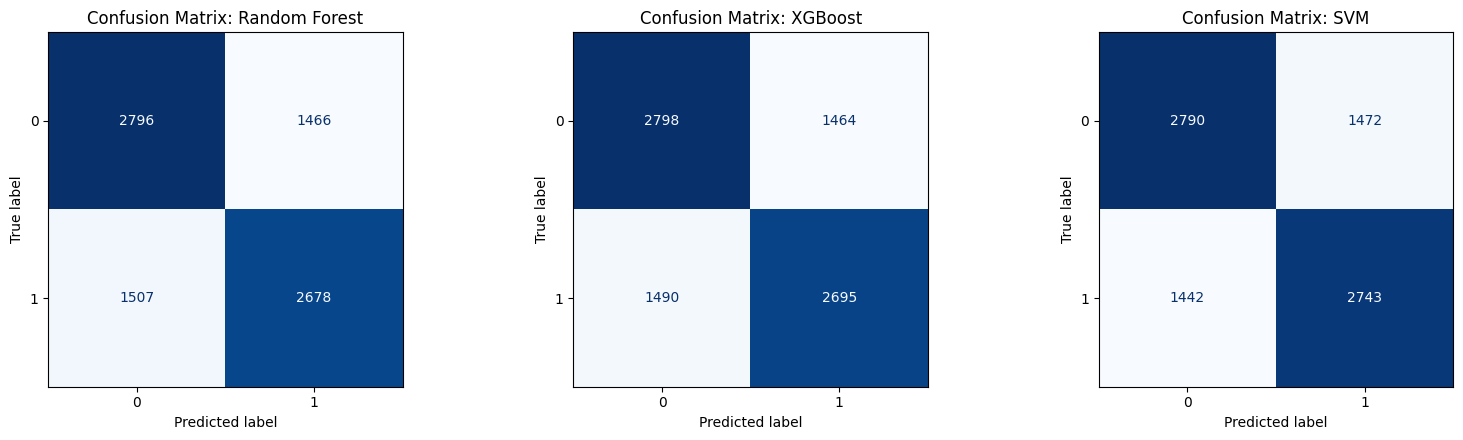

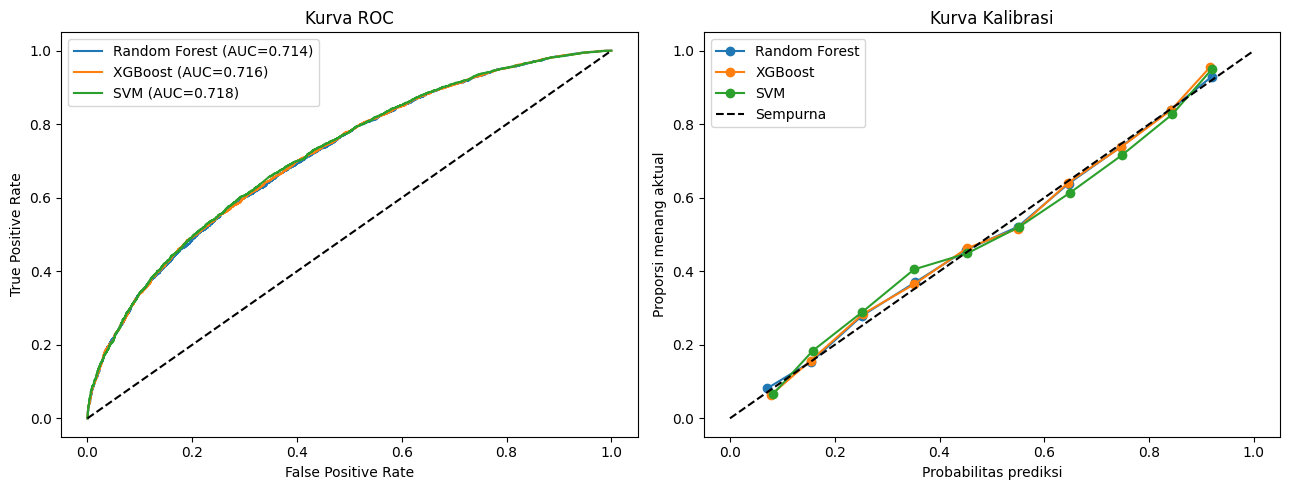

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, final_models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[n], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion Matrix: {n}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_confusion_matrix_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p):.3f})")
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10)
    axes[1].plot(mean_pred, frac_pos, marker="o", label=n)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title=L["roc"], xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].plot([0, 1], [0, 1], "k--", label=L["perfect"]); axes[1].set(title=L["calib"], xlabel=L["xlab"], ylabel=L["ylab"])
axes[0].legend(); axes[1].legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig2_roc_kalibrasi_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

In [13]:
# Uji McNemar: apakah selisih akurasi antar-model signifikan? (p < 0.05 = berbeda nyata)
from statsmodels.stats.contingency_tables import mcnemar
correct = {n: preds[n] == y_test for n in preds}
out = []
for a, b in combinations(preds, 2):
    ca, cb = correct[a], correct[b]
    table = [[(ca & cb).sum(), (ca & ~cb).sum()], [(~ca & cb).sum(), (~ca & ~cb).sum()]]
    res = mcnemar(table, exact=False, correction=True)
    out.append({"Pasangan": f"{a} vs {b}", "A benar, B salah": int((ca & ~cb).sum()), "A salah, B benar": int((~ca & cb).sum()),
                "Statistik": round(res.statistic, 4), "p-value": round(res.pvalue, 4),
                "Signifikan (0.05)": res.pvalue < 0.05})
mcnemar_df = pd.DataFrame(out)
mcnemar_df


,Pasangan,"A benar, B salah","A salah, B benar",Statistik,p-value,Signifikan (0.05)
0,Random Forest vs XGBoost,104,123,1.4273,0.2322,False
1,Random Forest vs SVM,231,290,6.4568,0.0111,True
2,XGBoost vs SVM,204,244,3.3951,0.0654,False


## 6. Interpretasi model (SHAP)

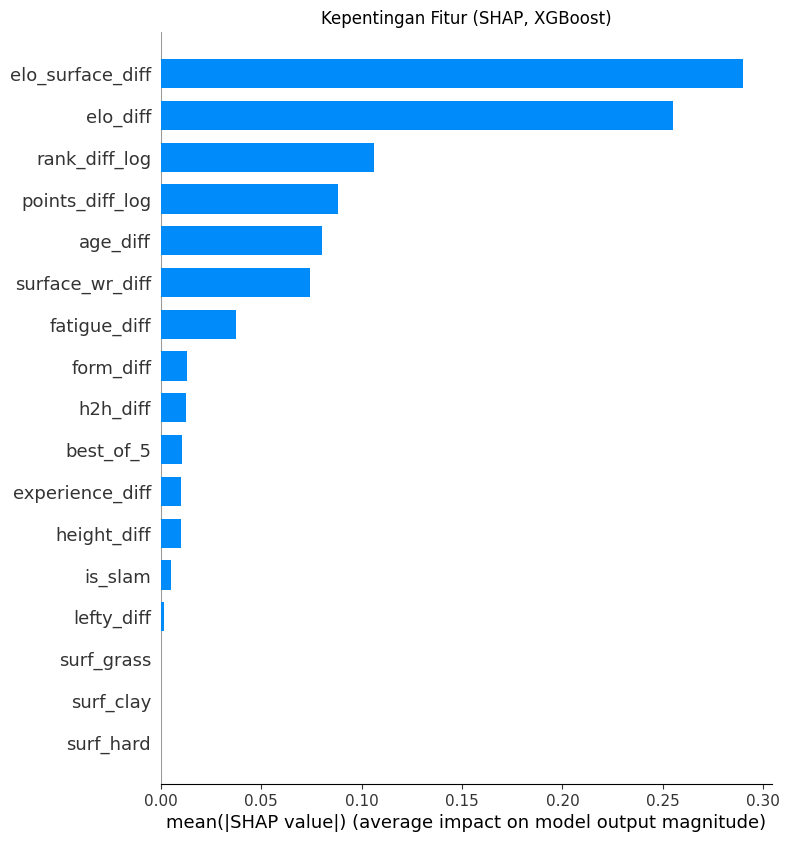

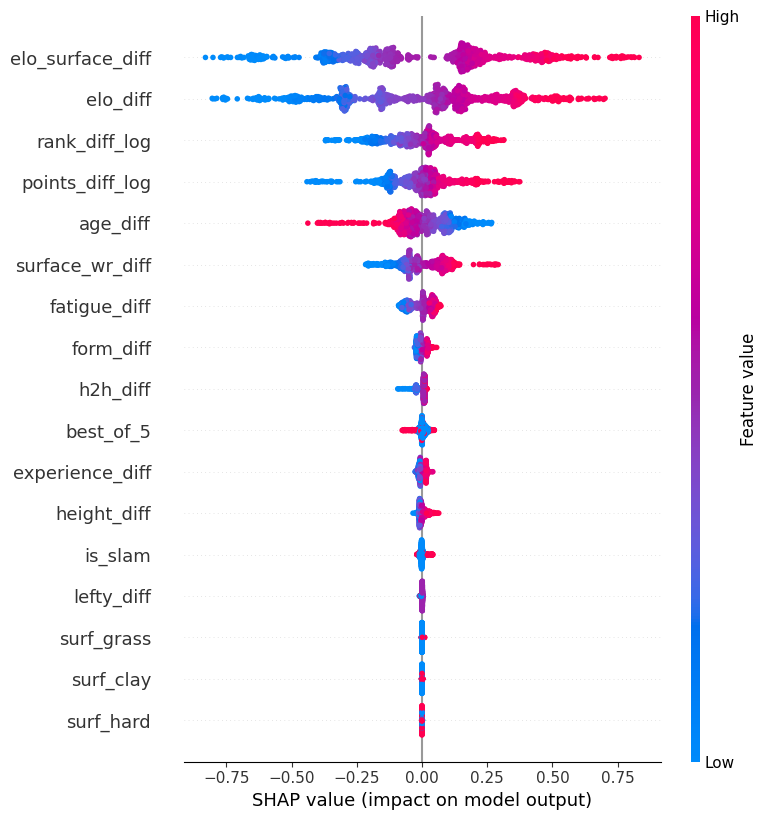

,mean_abs_SHAP
elo_surface_diff,0.2899
elo_diff,0.2553
rank_diff_log,0.1060
points_diff_log,0.0885
age_diff,0.0803
surface_wr_diff,0.0741
fatigue_diff,0.0376
form_diff,0.0130
h2h_diff,0.0127
best_of_5,0.0104


In [14]:
import shap
xgb_clf = final_models["XGBoost"].named_steps["clf"]
sample = X_test.sample(min(1000, len(X_test)), random_state=SEED)
shap_values = shap.TreeExplainer(xgb_clf).shap_values(sample)

shap.summary_plot(shap_values, sample, plot_type="bar", show=False); plt.title(L["shap"])
plt.savefig(f"{OUT_DIR}/fig3_shap_bar_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()
shap.summary_plot(shap_values, sample, show=False)
plt.savefig(f"{OUT_DIR}/fig4_shap_beeswarm_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

# tabel kepentingan fitur (rata-rata |SHAP|) untuk naskah
shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns).sort_values(ascending=False).round(4).rename("mean_abs_SHAP")
shap_imp.to_frame()

## 7. Simpan model

In [15]:
joblib.dump({"models": final_models, "features": FEATURES, "tracker": tr, "results": results},
            f"{SAVE_DIR}/tenis_model.joblib")
results.to_csv(f"{SAVE_DIR}/hasil_evaluasi.csv")
print("Tersimpan di", SAVE_DIR)

Tersimpan di /content/model_tenis


## 7b. Paket hasil untuk naskah

Menjalankan sel ini mengunduh satu berkas ZIP berisi semua tabel, catatan data, dan gambar 300 DPI. Cukup kirim berkas ZIP tersebut.

In [16]:
# Paket keluaran untuk naskah: tabel (CSV), catatan data (JSON), dan gambar 300 DPI -> satu berkas ZIP
import shutil
results_full.to_csv(f"{OUT_DIR}/tabel_hasil_metrik_ci.csv")
ci_table.to_csv(f"{OUT_DIR}/tabel_ci_bootstrap.csv")
diff_table.to_csv(f"{OUT_DIR}/tabel_selisih_akurasi.csv", index=False)
mcnemar_df.to_csv(f"{OUT_DIR}/tabel_mcnemar.csv", index=False)
shap_imp.to_csv(f"{OUT_DIR}/tabel_shap_importance.csv")
tuning_table.to_csv(f"{OUT_DIR}/tabel_tuning.csv")
with open(f"{OUT_DIR}/catatan_data_dan_konfigurasi.json", "w", encoding="utf-8") as f:
    json.dump({"info": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in info.items()},
               "parameter_terbaik": {k: {pk: (pv if isinstance(pv, (int, float, str, type(None))) else str(pv)) for pk, pv in v.items()}
                                     for k, v in best_params.items()},
               "ruang_pencarian": {k: {pk: [pv_ if isinstance(pv_, (int, float, str)) else str(pv_) for pv_ in pv] for pk, pv in g.items()}
                                for k, (_, g) in models.items()},
               "pengaturan": dict(START_YEAR=START_YEAR, END_YEAR=END_YEAR, TRAIN_START_YEAR=TRAIN_START_YEAR,
                                  TEST_START_DATE=TEST_START_DATE, MIN_PRIOR_MATCHES=MIN_PRIOR_MATCHES, DROP_RETIRED=DROP_RETIRED,
                                  N_TUNE=N_TUNE, N_ITER=N_ITER, B=B, B_AUC=B_AUC)},
              f, ensure_ascii=False, indent=2)
zip_path = shutil.make_archive(f"{SAVE_DIR}/hasil_naskah", "zip", OUT_DIR)
print("Isi paket:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_path)       # unduh lalu kirim berkas ZIP ini
except Exception:
    print("ZIP tersimpan di:", zip_path)

Isi paket: ['catatan_data_dan_konfigurasi.json', 'fig1_confusion_matrix_id.png', 'fig2_roc_kalibrasi_id.png', 'fig3_shap_bar_id.png', 'fig4_shap_beeswarm_id.png', 'tabel_ci_bootstrap.csv', 'tabel_hasil_metrik_ci.csv', 'tabel_mcnemar.csv', 'tabel_selisih_akurasi.csv', 'tabel_shap_importance.csv', 'tabel_tuning.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Aplikasi Gradio

Dua mode:
- **Pemain Terdaftar:** pilih dari daftar; fitur diambil otomatis dari riwayat data.
- **Pemain Kustom:** ketik nama bebas (mis. "Jefri") dan isi profilnya manual.
  Hasil mode ini hanyalah **estimasi**: model dilatih dari data profesional dan belum divalidasi untuk level amatir.

In [17]:
import gradio as gr

REF_DATE = df.tourney_date.max()                       # acuan untuk menghitung kelelahan 14 hari
BEST_MODEL = results.loc[list(final_models)].LogLoss.idxmin()
LEVELS = {"Grand Slam": True, "Turnamen lain": False}

# daftar pemain aktif (>= MIN_PRIOR_MATCHES laga dan bermain dalam 2 tahun terakhir data)
active = {pid: b["name"] for pid, b in tr.bio.items()
          if tr.n[pid] >= MIN_PRIOR_MATCHES and (REF_DATE - b["last_date"]).days <= 730}
name_to_id = {n: pid for pid, n in sorted(active.items(), key=lambda x: -tr.elo[x[0]])}   # urut Elo tertinggi
player_names = list(name_to_id)

def profile_registered(name, surface):
    pid = name_to_id[name]; b = tr.bio[pid]
    p = dict(rank=b["rank"], points=b["points"], age=b["age"], ht=b["ht"], lefty=float(b["hand"] == "L"))
    p.update(tr.dynamic(pid, surface, REF_DATE))
    return pid, p

def profile_custom(elo, rank, age, ht, hand, form_pct, surf_wr_pct, fatigue_h, n_matches):
    return dict(rank=rank if rank and rank > 0 else np.nan, points=np.nan, age=age, ht=ht, lefty=float(hand == "L"),
                elo=elo, elo_s=elo, form=form_pct / 100, surf_wr=surf_wr_pct / 100,
                fatigue=fatigue_h * 60, exp=int(n_matches))

def predict_pair(p1, p2, surface, best_of, is_slam, h2h_diff, model_name):
    X = pd.DataFrame([build_features(p1, p2, surface, best_of, is_slam, h2h_diff)])[FEATURES]
    return float(final_models[model_name].predict_proba(X)[0, 1])

def plot_prob(n1, n2, prob):
    fig, ax = plt.subplots(figsize=(7, 1.9))
    ax.barh(0, prob, color="#2a9d8f"); ax.barh(0, 1 - prob, left=prob, color="#e76f51")
    ax.text(prob / 2, 0, f"{n1}\n{prob:.1%}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(prob + (1 - prob) / 2, 0, f"{n2}\n{1 - prob:.1%}", ha="center", va="center", color="white", fontweight="bold")
    ax.axvline(0.5, color="white", ls="--", lw=1); ax.set_xlim(0, 1); ax.axis("off")
    ax.set_title("Peluang menang", fontsize=11); plt.tight_layout(); return fig

def plot_elo(id1, n1, id2, n2):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for pid, n in ((id1, n1), (id2, n2)):
        h = tr.elo_hist[pid]
        if h: ax.plot([d for d, _ in h], [e for _, e in h], label=n)
    ax.set(title="Tren Elo (tingkat performa)", ylabel="Elo"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); return fig

def compare_table(n1, p1, n2, p2):
    def fmt(p):
        return [round(p["elo"]), round(p["elo_s"]), "-" if pd.isna(p.get("rank")) else int(p["rank"]),
                f"{p['form']:.0%}", f"{p['surf_wr']:.0%}", round(p["fatigue"] / 60, 1), int(p["exp"])]
    labels = ["Elo umum", "Elo permukaan", "Ranking", "Form 10 laga", "Win rate permukaan", "Jam main (14 hari)", "Jumlah laga"]
    return pd.DataFrame({"Faktor": labels, n1: fmt(p1), n2: fmt(p2)})

def run_registered(n1, n2, surface, level, best_of, model_name):
    if not n1 or not n2 or n1 == n2:
        return None, None, "Pilih dua pemain yang berbeda.", None
    id1, p1 = profile_registered(n1, surface); id2, p2 = profile_registered(n2, surface)
    h2h = tr.h2h[(id1, id2)] - tr.h2h[(id2, id1)]
    prob = predict_pair(p1, p2, surface, int(best_of), LEVELS[level], h2h, model_name)
    txt = (f"### {n1}: **{prob:.1%}**  vs  {n2}: **{1 - prob:.1%}**\n"
           f"Model: {model_name} | Permukaan: {surface} | H2H (selisih kemenangan): {h2h:+d}\n\n"
           f"*Prediksi berbasis data hingga {REF_DATE.date()}. Untuk tujuan akademik, bukan untuk taruhan.*")
    return plot_prob(n1, n2, prob), plot_elo(id1, n1, id2, n2), txt, compare_table(n1, p1, n2, p2)

def run_custom(n1, e1, r1, a1, h1, hd1, f1, s1, fat1, m1,
               n2, e2, r2, a2, h2, hd2, f2, s2, fat2, m2, surface, level, best_of, model_name):
    n1, n2 = n1 or "Pemain A", n2 or "Pemain B"
    p1 = profile_custom(e1, r1, a1, h1, hd1, f1, s1, fat1, m1)
    p2 = profile_custom(e2, r2, a2, h2, hd2, f2, s2, fat2, m2)
    prob = predict_pair(p1, p2, surface, int(best_of), LEVELS[level], 0, model_name)
    txt = (f"### {n1}: **{prob:.1%}**  vs  {n2}: **{1 - prob:.1%}**\n"
           f"Model: {model_name} | Permukaan: {surface}\n\n"
           "**Estimasi, belum divalidasi untuk level amatir.** Model dilatih dari data ATP profesional.")
    return plot_prob(n1, n2, prob), txt, compare_table(n1, p1, n2, p2)

def player_inputs(tag, default_name):
    with gr.Column():
        gr.Markdown(f"**{tag}**")
        return [gr.Textbox(label="Nama", value=default_name),
                gr.Number(label="Elo internal (baru = 1500)", value=1500),
                gr.Number(label="Ranking (kosongkan bila tidak ada)", value=None),
                gr.Number(label="Usia", value=25), gr.Number(label="Tinggi (cm)", value=175),
                gr.Radio(["R", "L"], label="Tangan dominan", value="R"),
                gr.Slider(0, 100, value=50, label="Persen menang 10 laga terakhir (%)"),
                gr.Slider(0, 100, value=50, label="Persen menang di permukaan ini (%)"),
                gr.Number(label="Jam bermain 14 hari terakhir", value=0),
                gr.Number(label="Jumlah laga tercatat", value=15)]

SURFACES = ["Hard", "Clay", "Grass"]
with gr.Blocks(title="Prediksi Pemenang Tenis") as demo:
    gr.Markdown("# Prediksi Pemenang Tenis\nRandom Forest, XGBoost, dan SVM | data ATP (Jeff Sackmann)")
    with gr.Row():
        surface = gr.Radio(SURFACES, label="Permukaan", value="Hard")
        level = gr.Radio(list(LEVELS), label="Level turnamen", value="Turnamen lain")
        best_of = gr.Radio([3, 5], label="Best of", value=3)
        model_name = gr.Dropdown(list(final_models), label="Model", value=BEST_MODEL)
    with gr.Tab("Pemain Terdaftar"):
        with gr.Row():
            d1 = gr.Dropdown(player_names, label="Pemain A", value=player_names[0])
            d2 = gr.Dropdown(player_names, label="Pemain B", value=player_names[1])
        b1 = gr.Button("Prediksi", variant="primary")
        t1 = gr.Markdown(); pl1 = gr.Plot(); pl2 = gr.Plot(); tb1 = gr.Dataframe(label="Perbandingan faktor")
        b1.click(run_registered, [d1, d2, surface, level, best_of, model_name], [pl1, pl2, t1, tb1])
    with gr.Tab("Pemain Kustom"):
        with gr.Row():
            in1 = player_inputs("Pemain A", "Pemain A"); in2 = player_inputs("Pemain B", "Pemain B")
        b2 = gr.Button("Prediksi", variant="primary")
        t2 = gr.Markdown(); pl3 = gr.Plot(); tb2 = gr.Dataframe(label="Perbandingan faktor")
        b2.click(run_custom, in1 + in2 + [surface, level, best_of, model_name], [pl3, t2, tb2])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2781b8c54d7530760c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Catatan untuk skripsi

- **Ekspektasi akurasi:** pada uji dengan data asli (2023-2026), baseline ranking sekitar 63-64% dan model sekitar 65-66%. Selisih kecil itu wajar untuk tenis. Jika hasil > 75%, curigai leakage.
- **Batasan:** aturan cold-start (min. 10 laga), Elo awal 1500, usia dan ranking diambil dari laga terakhir, data ATP tingkat tur (tanpa Challenger/ITF).
- **Etika:** gunakan hanya untuk tujuan akademik, bukan taruhan. Cantumkan sitasi dataset (CC BY-NC-SA).
- **Pengembangan lanjut:** peluang langsung (Markov Chain), aplikasi mobile, lalu video (OCR papan skor + pose estimation).